# 11 · End-to-end: pointwise Llama reranking of the full-corpus lists (Phase 5, tasks 5.8–5.9)

Two first-stage lists per query, both of length 100:
- **Qwen3-Embedding top 100** over the full corpus (notebook 09).
- **The same list after co-citation expansion** with the setting chosen in notebook 10 (t = 5 seeds, bottom 10% replaced, raw counts, all leakage rules).

**Second stage.** Llama 3.2 3B Instruct scores every listed candidate **pointwise**: one (query, candidate) pair per call, at temperature 0, with the v2 prompt and text. The score is the probability-weighted 0–10 rating.
- Pointwise scoring cannot copy the list order, which was the failure mode of listwise reranking in v2.
- It is the same *kind* of stage as the deployed app's stage 2. The app's task (paper → researcher) and prompt differ, so this is evidence about the app, not a test of it.

**Variants.** The final score is α · Llama + (1 − α) · Qwen3-Embedding, both min-max normalized within the list.
- α = 0 is the first stage alone; α = 1 is Llama alone.
- **α is chosen on dev** (48 queries) by nDCG@10 on the Qwen3-Embedding list, then fixed for both lists on test.

**Metrics.** nDCG@10, MRR and R-precision, plus recall@10/20 inside the list (reranking cannot change recall@100). There are paired bootstrap CIs and Holm-corrected Wilcoxon tests against the Qwen3-Embedding first stage. **Attribution (5.9):** how many positives in the final top 10 and top 20 entered through the graph.

Scores are cached per (query, document) in `v2/runs_corpus/pointwise_llama.jsonl`; the two lists overlap except for the replaced slots, so each pair is scored once.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import numpy as np
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
T, B, NORM = 5, 0.1, "count"   # chosen on dev in notebook 10
K = 100
ALPHAS = [round(a, 1) for a in np.linspace(0, 1, 11)]
SECONDS_PER_CALL = 0.193      # pointwise Llama in v2 (runs/random/tac_600_1500/llama-pointwise, seed 0)

In [3]:
import json

from src.cograph import Rules
from src.expansion import cocitation_scores, grit_expand
from src.pipeline_v2 import EMB_CACHE
from src.retrieval import dense_matrix, load_phase5

S = load_phase5(RESEARCH)
g, labels, qids, idx, masks, pos_idx = S["g"], S["labels"], S["qids"], S["idx"], S["masks"], S["pos_idx"]
doc_ids = S["doc_ids"]
qrow = {q: i for i, q in enumerate(qids)}
dev_q = [q for q in qids if labels[q]["split"] == "dev"]
test_q = [q for q in qids if labels[q]["split"] == "test"]
qwen = dense_matrix("qwen", S["doc_texts"], S["query_texts"], EMB_CACHE / S["tag"])
with (RESEARCH / "v2" / "runs_corpus" / "stage1" / "qwen.jsonl").open() as f:
    top_qwen = {r["pi_id"]: np.array([idx[d] for d in r["top100"]]) for r in map(json.loads, f)}

lists = {"Qwen3-Embedding": top_qwen, "Co-citation expanded": {}}
graph_added = {}
for q in qids:
    top = top_qwen[q]
    gs = cocitation_scores(g, top[:T], g.allowed(q, labels[q]["date"], Rules()), NORM)
    new, added = grit_expand(top, T, B, gs, masks[q].copy(), qwen[qrow[q]])
    lists["Co-citation expanded"][q], graph_added[q] = new, set(added.tolist())
rec = {name: np.mean([np.isin(pos_idx[q], L[q]).mean() for q in test_q]) * 100 for name, L in lists.items()}
print({k: round(v, 1) for k, v in rec.items()})
assert abs(rec["Co-citation expanded"] - 64.9) < 0.05, "expanded lists must match notebook 10"

{'Qwen3-Embedding': np.float64(64.0), 'Co-citation expanded': np.float64(64.9)}


### Pointwise scoring

In [4]:
to_score = {q: sorted({doc_ids[i] for L in lists.values() for i in L[q]}) for q in qids}
n_calls = sum(map(len, to_score.values()))
print(f"pairs to score: {n_calls} ({n_calls / len(qids):.0f} per query); "
      f"estimate at {SECONDS_PER_CALL} s/call: {n_calls * SECONDS_PER_CALL / 60:.0f} min "
      f"(dev {sum(len(to_score[q]) for q in dev_q) * SECONDS_PER_CALL / 60:.0f}, test {sum(len(to_score[q]) for q in test_q) * SECONDS_PER_CALL / 60:.0f})")

pairs to score: 17939 (108 per query); estimate at 0.193 s/call: 58 min (dev 17, test 41)


In [5]:
import time

from tqdm.auto import tqdm

from src import jan
from src.rerank import PointwiseCache

assert jan.JAN_MODEL_MAP["llama"] in jan.list_models(), "llama-server must serve Llama 3.2 3B"
cache = PointwiseCache(RESEARCH / "v2" / "runs_corpus" / "pointwise_llama.jsonl")
text_of = dict(zip(doc_ids, S["doc_texts"]))
t0, new = time.time(), 0
for q in tqdm(dev_q + test_q, desc="pointwise Llama"):  # dev first, so tuning data exists early
    new += cache.ensure(q, S["query_texts"][qrow[q]], to_score[q], text_of.get)
elapsed = time.time() - t0
print(f"new calls: {new} in {elapsed / 60:.1f} min ({elapsed / max(new, 1):.3f} s/call)")

new calls: 0 in 0.0 min (0.039 s/call)


In [6]:
status = pd.Series([cache.scores[(q, d)]["status"] for q in qids for d in to_score[q]]).value_counts()
scoring = pd.Series([cache.scores[(q, d)]["scoring"] for q in qids for d in to_score[q]]).value_counts(dropna=False)
print("call status:", status.to_dict(), "| scoring:", scoring.to_dict())

call status: {'ok': 17939} | scoring: {'logprobs': 17939}


### How well does the Llama score separate positives from other listed candidates?

In [7]:
from sklearn.metrics import roc_auc_score

rows = []
for q in qids:
    docs = to_score[q]
    y = np.isin([idx[d] for d in docs], pos_idx[q])
    if 0 < y.sum() < len(y):
        llm = cache.get(q, docs)
        emb = qwen[qrow[q]][[idx[d] for d in docs]]
        rows.append({"split": labels[q]["split"], "auc_llama": roc_auc_score(y, llm), "auc_qwen": roc_auc_score(y, emb),
                     "llama_pos": llm[y].mean(), "llama_other": llm[~y].mean()})
sep = pd.DataFrame(rows)
sep.groupby("split").mean().round(3)

,auc_llama,auc_qwen,llama_pos,llama_other
split,,,,
dev,0.635,0.770,5.991,5.717
test,0.663,0.761,6.027,5.701


### α on dev

In [8]:
from src.rerank import fuse_order
from src.retrieval import query_metrics

def evaluate(list_name, alpha, queries):
    out = {}
    for q in queries:
        order = lists[list_name][q]
        docs = [doc_ids[i] for i in order]
        new = fuse_order(order, cache.get(q, docs), qwen[qrow[q]][order], alpha)
        m, _ = query_metrics(new, pos_idx[q])
        out[q] = {**m, "order": new}
    return out

dev_rows = [{"list": name, "alpha": a, **pd.DataFrame(evaluate(name, a, dev_q)).T[["ndcg@10", "mrr", "rprec"]].astype(float).mean()}
            for name in lists for a in ALPHAS]
dev_tab = pd.DataFrame(dev_rows)
qdev = dev_tab[dev_tab["list"] == "Qwen3-Embedding"].sort_values(["ndcg@10", "alpha"], ascending=[False, True])
ALPHA = float(qdev.iloc[0]["alpha"])
print(f"alpha chosen on dev (Qwen3-Embedding list, nDCG@10): {ALPHA}")
dev_tab.pivot(index="alpha", columns="list", values="ndcg@10").round(3)

alpha chosen on dev (Qwen3-Embedding list, nDCG@10): 0.1


list,Co-citation expanded,Qwen3-Embedding
alpha,,
0.0,0.344,0.344
0.1,0.344,0.344
0.2,0.342,0.340
0.3,0.334,0.340
0.4,0.329,0.328
0.5,0.308,0.327
0.6,0.292,0.307
0.7,0.271,0.292
0.8,0.247,0.263


### Test

In [9]:
from scipy.stats import wilcoxon

from src.stats_v2 import boot_ci, holm

CONDS = {
    "Qwen3-Embedding (first stage)": ("Qwen3-Embedding", 0.0),
    "Qwen3-Embedding → Llama only": ("Qwen3-Embedding", 1.0),
    f"Qwen3-Embedding → fused (α = {ALPHA})": ("Qwen3-Embedding", ALPHA),
    "Expanded (first stage)": ("Co-citation expanded", 0.0),
    "Expanded → Llama only": ("Co-citation expanded", 1.0),
    f"Expanded → fused (α = {ALPHA})": ("Co-citation expanded", ALPHA),
}
METRICS = ["ndcg@10", "mrr", "rprec", "recall@10", "recall@20", "recall@100"]
res = {name: evaluate(lst, a, test_q) for name, (lst, a) in CONDS.items()}
base = pd.DataFrame(res["Qwen3-Embedding (first stage)"]).T
rng = np.random.default_rng(42)
rows = []
for name, r in res.items():
    d = pd.DataFrame(r).T
    row = {"condition": name}
    for m in METRICS:
        x = d[m].astype(float).to_numpy()
        lo, hi = boot_ci(x, rng)
        row[m], row[f"{m}_ci"] = x.mean(), f"[{lo:.3f}, {hi:.3f}]" if m != "rprec" else f"[{lo:.1f}, {hi:.1f}]"
    for m in ("ndcg@10", "rprec"):
        diff = d[m].astype(float).to_numpy() - base[m].astype(float).to_numpy()
        lo, hi = boot_ci(diff, rng)
        row[f"d_{m}"], row[f"d_{m}_ci"] = diff.mean(), f"[{lo:+.3f}, {hi:+.3f}]" if m != "rprec" else f"[{lo:+.1f}, {hi:+.1f}]"
        row[f"p_{m}"] = wilcoxon(diff).pvalue if np.any(diff != 0) else np.nan
    rows.append(row)
test_tab = pd.DataFrame(rows)
for m in ("ndcg@10", "rprec"):
    ok = test_tab[f"p_{m}"].notna()
    test_tab.loc[ok, f"p_{m}_holm"] = holm(test_tab.loc[ok, f"p_{m}"].tolist())
test_tab.round({c: 3 for c in test_tab.columns if not c.startswith("p_")})  # p-values unrounded

,condition,ndcg@10,ndcg@10_ci,mrr,mrr_ci,rprec,rprec_ci,recall@10,recall@10_ci,recall@20,recall@20_ci,recall@100,recall@100_ci,d_ndcg@10,d_ndcg@10_ci,p_ndcg@10,d_rprec,d_rprec_ci,p_rprec,p_ndcg@10_holm,p_rprec_holm
0,Qwen3-Embedding (first stage),0.340,"[0.292, 0.389]",0.608,"[0.531, 0.683]",25.079,"[21.2, 29.1]",0.311,"[0.265, 0.360]",0.409,"[0.359, 0.460]",0.640,"[0.588, 0.693]",0.000,"[+0.000, +0.000]",NaN,0.000,"[+0.0, +0.0]",NaN,NaN,NaN
1,Qwen3-Embedding → Llama only,0.175,"[0.141, 0.213]",0.317,"[0.256, 0.380]",14.294,"[11.2, 17.6]",0.187,"[0.153, 0.225]",0.276,"[0.234, 0.319]",0.640,"[0.587, 0.693]",-0.164,"[-0.204, -0.126]",1.003007e-11,-10.785,"[-14.3, -7.5]",1.091889e-07,3.146279e-11,3.275667e-07
2,Qwen3-Embedding → fused (α = 0.1),0.336,"[0.288, 0.383]",0.595,"[0.519, 0.672]",25.038,"[21.1, 29.1]",0.311,"[0.265, 0.360]",0.415,"[0.367, 0.465]",0.640,"[0.587, 0.693]",-0.004,"[-0.009, +0.001]",2.404217e-01,-0.041,"[-0.4, +0.3]",4.614510e-01,4.808434e-01,4.614510e-01
3,Expanded (first stage),0.340,"[0.292, 0.389]",0.609,"[0.535, 0.685]",25.079,"[21.3, 29.2]",0.311,"[0.266, 0.360]",0.409,"[0.360, 0.461]",0.649,"[0.599, 0.698]",0.000,"[+0.000, +0.000]",NaN,0.000,"[+0.0, +0.0]",NaN,NaN,NaN
4,Expanded → Llama only,0.173,"[0.138, 0.212]",0.315,"[0.254, 0.377]",14.018,"[11.0, 17.4]",0.186,"[0.150, 0.224]",0.277,"[0.235, 0.320]",0.649,"[0.597, 0.698]",-0.166,"[-0.205, -0.128]",7.865699e-12,-11.061,"[-14.6, -7.7]",3.782256e-08,3.146279e-11,1.512903e-07
5,Expanded → fused (α = 0.1),0.336,"[0.288, 0.383]",0.597,"[0.520, 0.672]",24.753,"[20.9, 28.9]",0.310,"[0.264, 0.358]",0.413,"[0.363, 0.463]",0.649,"[0.598, 0.699]",-0.003,"[-0.010, +0.003]",4.359497e-01,-0.326,"[-0.9, +0.2]",1.197949e-01,4.808434e-01,2.395899e-01


### Attribution (5.9): positives near the top that came through the graph

In [10]:
for name in [n for n in CONDS if n.startswith("Expanded")]:
    r = res[name]
    for k in (10, 20, 100):
        found = sum(int(np.isin(r[q]["order"][:k], pos_idx[q]).sum()) for q in test_q)
        via = sum(len(set(r[q]["order"][:k].tolist()) & graph_added[q] & set(pos_idx[q])) for q in test_q)
        print(f"{name:40s} top {k:3d}: {found:4d} positives, {via:3d} via the graph ({via / max(found, 1):.1%})")

Expanded (first stage)                   top  10:  254 positives,   0 via the graph (0.0%)
Expanded (first stage)                   top  20:  332 positives,   0 via the graph (0.0%)
Expanded (first stage)                   top 100:  548 positives,  20 via the graph (3.6%)
Expanded → Llama only                    top  10:  147 positives,   0 via the graph (0.0%)
Expanded → Llama only                    top  20:  228 positives,   4 via the graph (1.8%)
Expanded → Llama only                    top 100:  548 positives,  20 via the graph (3.6%)
Expanded → fused (α = 0.1)               top  10:  253 positives,   0 via the graph (0.0%)
Expanded → fused (α = 0.1)               top  20:  335 positives,   0 via the graph (0.0%)
Expanded → fused (α = 0.1)               top 100:  548 positives,  20 via the graph (3.6%)


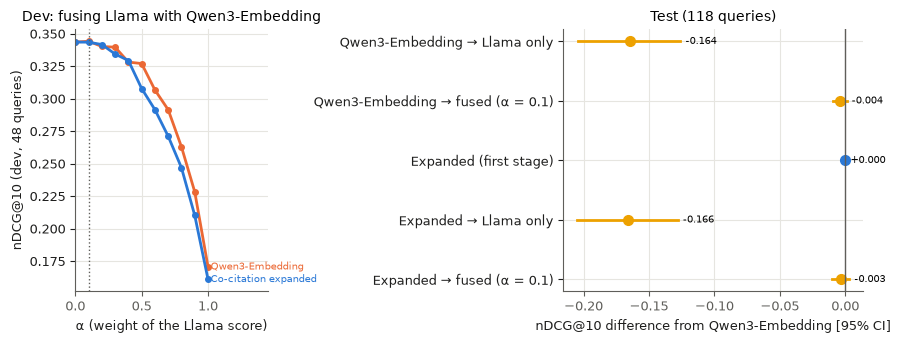

In [11]:
import matplotlib.pyplot as plt

from src.figures import FAMILY_COLOR, INK_2, SLOTS

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.5), gridspec_kw={"width_ratios": [0.9, 1.4]})
ax = axes[0]
for name, color in (("Qwen3-Embedding", FAMILY_COLOR["Embedding"]), ("Co-citation expanded", SLOTS[0])):
    d = dev_tab[dev_tab["list"] == name]
    ax.plot(d.alpha, d["ndcg@10"], "o-", color=color, ms=4)
    ax.text(1.02, d["ndcg@10"].iloc[-1], name, color=color, fontsize=7.5, va="center")
ax.axvline(ALPHA, color=INK_2, ls=":", lw=1)
ax.set_xlabel("α (weight of the Llama score)")
ax.set_ylabel("nDCG@10 (dev, 48 queries)")
ax.set_title("Dev: fusing Llama with Qwen3-Embedding")
ax.set_xlim(0, 1.45)

ax = axes[1]
show = test_tab[test_tab.condition != "Qwen3-Embedding (first stage)"].reset_index(drop=True)
for i, r in show.iterrows():
    lo, hi = [float(v) for v in r["d_ndcg@10_ci"].strip("[]").split(", ")]
    color = FAMILY_COLOR["LLM"] if "Llama" in r.condition or "fused" in r.condition else SLOTS[0]
    ax.plot([lo, hi], [i, i], color=color, lw=2)
    ax.plot(r["d_ndcg@10"], i, "o", color=color)
    ax.text(max(hi, r["d_ndcg@10"]) + 0.004, i, f"{r['d_ndcg@10']:+.3f}", va="center", fontsize=7.5)
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(range(len(show)), show.condition)
ax.invert_yaxis()
ax.set_xlabel("nDCG@10 difference from Qwen3-Embedding [95% CI]")
ax.set_title("Test (118 queries)")
fig.tight_layout()
save(fig, "11_end_to_end")
plt.show()

### Findings

- **Scoring.** 17,939 (query, candidate) pairs, 108 per query: the union of both lists. All calls returned status ok with logprob scoring.
  - The scoring ran in two parts: 3,052 pairs before an interruption, then 14,887 in 87.4 min (0.352 s per call). The resumed run's cell above therefore shows 0 new calls.
  - That is slower than the 0.193 s measured in v2.
- **Llama separates positives from the other listed candidates only weakly.** Within the lists, the AUC is 0.663 on test against 0.761 for Qwen3-Embedding's own scores. The mean Llama score is 6.03 for cited papers and 5.70 for the rest.
- **Dev α.** nDCG@10 falls steadily as the Llama weight grows. α = 0.1 is chosen and is level with the first stage alone (0.344).
- **Test, Qwen3-Embedding list** (118 queries).
  - **Llama alone lowers nDCG@10 from 0.340 to 0.175** (−0.164 [−0.204, −0.126], Holm p = 3.1e-11) and R-precision from 25.1% to 14.3%.
  - The dev-chosen fusion (α = 0.1) changes nothing measurable: −0.004 [−0.009, +0.001], p = 0.24, Holm 0.48.
- **Test, co-citation expanded list.** The same picture: Llama alone −0.166, fusion −0.003 (not significant).
  - The expansion's +0.8 recall@100 (notebook 10) sits at the bottom of the list. The fused ranking puts **no** graph-recovered positive into the top 10 or top 20; Llama alone puts 4 into the top 20 (5.9).
- **Conclusion.** A full-corpus first stage with Qwen3-Embedding is not improved by pointwise Llama 3.2 3B reranking: used alone it costs about half of nDCG@10, and fused it adds nothing. This matches v2, where pointwise Llama scored below every embedding model.
  - For the deployed app, whose stage 2 is pointwise Llama 3.2 3B, this is evidence that the stage does not help. The app's task and prompt differ, so a direct test belongs to Phase 6B.
- **Figure.** `11_end_to_end`.
